In [1]:

from google.colab import drive
drive.mount('/content/drive5')


Mounted at /content/drive5


In [2]:

from pathlib import Path
import json
import pandas as pd

# Project paths
PROJECT = Path("/content/drive5/MyDrive/Ocular_Project")
RESULTS = PROJECT / "results/IITD"
MODELS = PROJECT / "models/IITD"

OUT_DIR = RESULTS / "notebook12_membership_inference"
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert PROJECT.exists(), f"Project folder not found: {PROJECT}"

print("=" * 65)
print("NOTEBOOK 12 — MEMBERSHIP INFERENCE ATTACK")
print("=" * 65)
print("Project:", PROJECT)
print("Output:", OUT_DIR)

# Check relevant existing artifacts
checks = {
    "Baseline checkpoint": MODELS / "IITD_baseline_resnet18_best.pth",
    "Notebook 10 original-only checkpoint": MODELS / "IITD_notebook10_original_only_resnet18.pth",
    "Notebook 10 traditional checkpoint": MODELS / "IITD_notebook10_original_plus_traditional_resnet18.pth",
    "Notebook 10 GAN checkpoint": MODELS / "IITD_notebook10_original_plus_GAN_exploratory_resnet18.pth",
    "Original split manifest": RESULTS / "notebook09_dataset_augmentation/IITD_original_split_manifest.csv",
    "Recognition comparison CSV": RESULTS / "notebook10_recognition_augmented/IITD_recognition_augmented_comparison.csv",
    "Data verification JSON": RESULTS / "notebook10_recognition_augmented/IITD_recognition_data_verification.json",
}

print("\nARTIFACT CHECK")
for label, path in checks.items():
    print(f"{'FOUND' if path.is_file() else 'MISSING'} | {label} | {path.name}")

# Inspect the original split manifest if available
manifest_path = checks["Original split manifest"]
if manifest_path.is_file():
    manifest = pd.read_csv(manifest_path)
    print("\nORIGINAL SPLIT MANIFEST")
    print("Shape:", manifest.shape)
    print("Columns:", manifest.columns.tolist())
    print(manifest.head(5).to_string(index=False))

# Inspect Notebook 10 comparison results if available
comparison_path = checks["Recognition comparison CSV"]
if comparison_path.is_file():
    comparison = pd.read_csv(comparison_path)
    print("\nNOTEBOOK 10 RECOGNITION RESULTS")
    print(comparison.to_string(index=False))

# Inspect the saved data-verification record
verification_path = checks["Data verification JSON"]
if verification_path.is_file():
    try:
        with open(verification_path, "r") as f:
            verification = json.load(f)
        print("\nNOTEBOOK 10 DATA VERIFICATION")
        print(json.dumps(verification, indent=2)[:5000])
    except Exception as e:
        print("Could not parse verification JSON:", e)

print("\nSetup and inspection complete.")
print("No model training or attack has been run yet.")


NOTEBOOK 12 — MEMBERSHIP INFERENCE ATTACK
Project: /content/drive5/MyDrive/Ocular_Project
Output: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook12_membership_inference

ARTIFACT CHECK
FOUND | Baseline checkpoint | IITD_baseline_resnet18_best.pth
FOUND | Notebook 10 original-only checkpoint | IITD_notebook10_original_only_resnet18.pth
FOUND | Notebook 10 traditional checkpoint | IITD_notebook10_original_plus_traditional_resnet18.pth
FOUND | Notebook 10 GAN checkpoint | IITD_notebook10_original_plus_GAN_exploratory_resnet18.pth
FOUND | Original split manifest | IITD_original_split_manifest.csv
FOUND | Recognition comparison CSV | IITD_recognition_augmented_comparison.csv
FOUND | Data verification JSON | IITD_recognition_data_verification.json

ORIGINAL SPLIT MANIFEST
Shape: (2180, 29)
Columns: ['image_path', 'relative_path', 'filename', 'subject_original', 'eye_original', 'capture_id_original', 'extension', 'valid_image', 'width_original', 'height_original', 'mode_original'

Device: cpu
Local sample prepared: 200 members + 200 non-members
Inference complete in 47.2 seconds


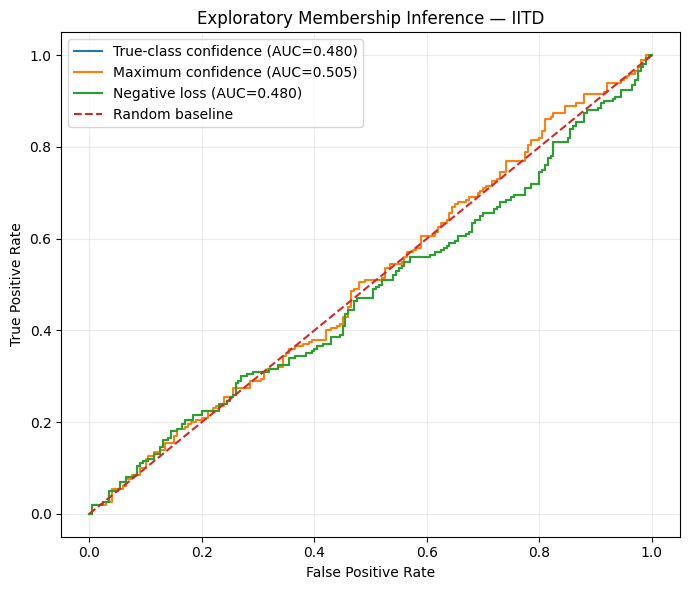


ATTACK METRICS


,attack_score,roc_auc,balanced_accuracy,threshold_selected_on_evaluation_sample,tpr_at_or_below_5pct_fpr
0,true_class_confidence,0.4799,0.5175,0.5285,0.055
1,max_confidence,0.5055,0.5250,0.1521,0.055
2,negative_loss,0.4799,0.5175,-0.6377,0.055



MEMBER VS NON-MEMBER


,membership,sample_count,mean_loss,mean_true_class_confidence,mean_max_confidence,accuracy,group
0,0,200,1.8401,0.2817,0.3657,0.555,test_nonmembers
1,1,200,1.9518,0.2760,0.3687,0.485,training_members



SAVED OUTPUTS
IITD_membership_attack_metrics.csv (299 bytes)
IITD_membership_attack_per_example_scores.csv (28,367 bytes)
IITD_membership_attack_roc.png (82,147 bytes)
IITD_membership_attack_summary.json (1,456 bytes)
IITD_membership_member_vs_nonmember_summary.csv (269 bytes)


In [5]:

import json, time, shutil, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score

# ---------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAMPLE_PER_GROUP = 200
BATCH_SIZE = 64

PROJECT = Path("/content/drive5/MyDrive/Ocular_Project")
RESULTS = PROJECT / "results/IITD"
MODELS = PROJECT / "models/IITD"
OUT_DIR = RESULTS / "notebook12_membership_inference"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = RESULTS / "notebook09_dataset_augmentation/IITD_original_split_manifest.csv"
CHECKPOINT_PATH = MODELS / "IITD_baseline_resnet18_best.pth"
IMAGE_ROOT = RESULTS / "notebook02_preprocessing/images_224"
LOCAL_ROOT = Path("/content/IITD_images_224")

# ---------------------------------------------------------
# 2. Read manifest and sample members/non-members
# ---------------------------------------------------------
manifest = pd.read_csv(MANIFEST_PATH)
manifest = manifest[
    manifest["path_exists"].astype(bool)
    & manifest["valid_image"].astype(bool)
].copy()

train_df = manifest[manifest["split"].astype(str).str.lower() == "train"].copy()
test_df = manifest[manifest["split"].astype(str).str.lower() == "test"].copy()

def resolve_path(row):
    return IMAGE_ROOT / Path(str(row["original_relative_path"])).with_suffix(".png")

train_df["source_path"] = train_df.apply(resolve_path, axis=1)
test_df["source_path"] = test_df.apply(resolve_path, axis=1)

# Deterministic balanced sample
train_df = train_df.sample(
    n=min(SAMPLE_PER_GROUP, len(train_df)), random_state=SEED
).copy()
test_df = test_df.sample(
    n=min(SAMPLE_PER_GROUP, len(test_df)), random_state=SEED
).copy()

# ---------------------------------------------------------
# 3. Copy only the sampled images to local Colab storage
# ---------------------------------------------------------
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
for group, frame in [("members", train_df), ("nonmembers", test_df)]:
    target_dir = LOCAL_ROOT / group
    target_dir.mkdir(parents=True, exist_ok=True)
    local_paths = []

    for i, src in enumerate(frame["source_path"]):
        dst = target_dir / f"{i:04d}.png"
        if not dst.exists():
            if not src.is_file():
                raise FileNotFoundError(f"Missing preprocessed image: {src}")
            shutil.copy2(src, dst)
        local_paths.append(dst)

    frame["local_path"] = local_paths

print("Device:", DEVICE)
print("Local sample prepared:", len(train_df), "members +",
      len(test_df), "non-members")

# ---------------------------------------------------------
# 4. Load baseline checkpoint
# ---------------------------------------------------------
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

class SampleDataset(Dataset):
    def __init__(self, frame, membership):
        self.frame = frame.reset_index(drop=True)
        self.membership = membership

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["local_path"]) as im:
            x = transform(im.convert("L"))
        return x, int(row["label"]), str(row["filename"]), self.membership

num_classes = int(manifest["label"].max()) + 1
model = models.resnet18(weights=None)
model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
model.fc = nn.Linear(model.fc.in_features, num_classes)

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location="cpu", weights_only=False
)
if "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]
elif "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

if any(k.startswith("module.") for k in checkpoint):
    checkpoint = {k.replace("module.", "", 1): v for k, v in checkpoint.items()}

model.load_state_dict(checkpoint)
model.to(DEVICE).eval()

# ---------------------------------------------------------
# 5. Batched inference on local images
# ---------------------------------------------------------
all_frames = [
    SampleDataset(train_df, 1),
    SampleDataset(test_df, 0)
]
records = []
start = time.time()

with torch.inference_mode():
    for dataset in all_frames:
        loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        for images, labels, filenames, membership in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            losses = nn.functional.cross_entropy(logits, labels, reduction="none")
            probs = torch.softmax(logits, dim=1)
            true_conf = probs.gather(1, labels[:, None]).squeeze(1)

            for i in range(len(labels)):
                records.append({
                    "membership": int(membership[i]),
                    "filename": filenames[i],
                    "loss": float(losses[i].cpu()),
                    "true_class_confidence": float(true_conf[i].cpu()),
                    "max_confidence": float(probs[i].max().cpu()),
                    "correct": int(logits[i].argmax().item() == labels[i].item())
                })

scores = pd.DataFrame(records)
print(f"Inference complete in {time.time()-start:.1f} seconds")

# ---------------------------------------------------------
# 6. Attack evaluation
# ---------------------------------------------------------
y = scores["membership"].to_numpy()
attack_rows = []

for name, raw_score in [
    ("true_class_confidence", scores["true_class_confidence"].to_numpy()),
    ("max_confidence", scores["max_confidence"].to_numpy()),
    ("negative_loss", -scores["loss"].to_numpy())
]:
    auc = float(roc_auc_score(y, raw_score))
    fpr, tpr, thresholds = roc_curve(y, raw_score)
    balanced = (tpr + 1 - fpr) / 2
    best = int(np.argmax(balanced))
    under5 = np.where(fpr <= 0.05)[0]

    attack_rows.append({
        "attack_score": name,
        "roc_auc": auc,
        "balanced_accuracy": float(balanced[best]),
        "threshold_selected_on_evaluation_sample": float(thresholds[best]),
        "tpr_at_or_below_5pct_fpr": float(tpr[under5[-1]]) if len(under5) else 0.0
    })

attack_df = pd.DataFrame(attack_rows)
group_summary = scores.groupby("membership").agg(
    sample_count=("membership", "size"),
    mean_loss=("loss", "mean"),
    mean_true_class_confidence=("true_class_confidence", "mean"),
    mean_max_confidence=("max_confidence", "mean"),
    accuracy=("correct", "mean")
).reset_index()
group_summary["group"] = group_summary["membership"].map(
    {1: "training_members", 0: "test_nonmembers"}
)

# ---------------------------------------------------------
# 7. Save outputs to Drive
# ---------------------------------------------------------
scores.to_csv(OUT_DIR / "IITD_membership_attack_per_example_scores.csv", index=False)
attack_df.to_csv(OUT_DIR / "IITD_membership_attack_metrics.csv", index=False)
group_summary.to_csv(OUT_DIR / "IITD_membership_member_vs_nonmember_summary.csv", index=False)

plt.figure(figsize=(7, 6))
for name, raw_score in [
    ("True-class confidence", scores["true_class_confidence"].to_numpy()),
    ("Maximum confidence", scores["max_confidence"].to_numpy()),
    ("Negative loss", -scores["loss"].to_numpy())
]:
    fpr, tpr, _ = roc_curve(y, raw_score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y, raw_score):.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exploratory Membership Inference — IITD")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plot_path = OUT_DIR / "IITD_membership_attack_roc.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

summary = {
    "experiment": "Fast exploratory score-based membership inference",
    "checkpoint": str(CHECKPOINT_PATH),
    "member_count": int((y == 1).sum()),
    "nonmember_count": int((y == 0).sum()),
    "sampled_images_only": True,
    "model_retrained": False,
    "attack_metrics": attack_rows,
    "limitations": [
        "Only a deterministic sample of 200 members and 200 non-members was evaluated.",
        "Thresholds were selected on the evaluation sample and are descriptive, not unbiased deployment estimates.",
        "Train and test images may differ in content or acquisition conditions.",
        "Attack AUC does not by itself prove disclosure of personal information.",
        "Near-chance results do not prove the absence of privacy leakage."
    ]
}
with open(OUT_DIR / "IITD_membership_attack_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nATTACK METRICS")
display(attack_df.round(4))
print("\nMEMBER VS NON-MEMBER")
display(group_summary.round(4))
print("\nSAVED OUTPUTS")
for p in sorted(OUT_DIR.iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")


In [6]:

import json

expected = [
    "IITD_membership_attack_per_example_scores.csv",
    "IITD_membership_attack_metrics.csv",
    "IITD_membership_member_vs_nonmember_summary.csv",
    "IITD_membership_attack_summary.json",
    "IITD_membership_attack_roc.png",
]

print("NOTEBOOK 12 — FINAL VERIFICATION")
for name in expected:
    path = OUT_DIR / name
    print(f"{'OK' if path.is_file() else 'MISSING'}: {name}")

with open(OUT_DIR / "IITD_membership_attack_summary.json") as f:
    json.load(f)

print("\nSummary JSON is valid.")
print("Remember to save the notebook with Cmd + S.")


NOTEBOOK 12 — FINAL VERIFICATION
OK: IITD_membership_attack_per_example_scores.csv
OK: IITD_membership_attack_metrics.csv
OK: IITD_membership_member_vs_nonmember_summary.csv
OK: IITD_membership_attack_summary.json
OK: IITD_membership_attack_roc.png

Summary JSON is valid.
Remember to save the notebook with Cmd + S.



# Membership Inference Attack — Results and Conclusion

## Objective

This experiment investigates whether simple confidence- and loss-based scores can distinguish training-member images from held-out test non-member images using the existing IITD baseline ResNet18 checkpoint.

## Experimental Setup

- Model: Existing IITD baseline ResNet18 checkpoint.
- Members: 200 sampled images from the original training split.
- Non-members: 200 sampled images from the held-out test split.
- Attack scores: True-class confidence, maximum predicted confidence, and negative cross-entropy loss.
- Execution: CPU inference; no model retraining.

## Results

| Attack score | ROC-AUC | Balanced accuracy |
|---|---:|---:|
| True-class confidence | 0.4799 | 0.5175 |
| Maximum confidence | 0.5055 | 0.5250 |
| Negative loss | 0.4799 | 0.5175 |

The ROC-AUC values are close to 0.5, the reference value for random ranking. Maximum confidence produced an AUC of approximately 0.506, while true-class confidence and negative loss produced AUC values of approximately 0.480.

In this sample, the tested scores show little ability to distinguish members from non-members.

## Member vs Non-Member Behaviour

- Training members: mean loss 1.9518, mean maximum confidence 0.3687, accuracy 48.5%.
- Test non-members: mean loss 1.8401, mean maximum confidence 0.3657, accuracy 55.5%.

The observed pattern does not show the conventional pattern of lower average loss on training members. The difference should not be interpreted as evidence of stronger privacy or generalization without further controlled experiments.

## Limitations

- Only 200 members and 200 non-members were sampled.
- The train and test sets may differ in image content or acquisition conditions.
- Thresholds and balanced accuracy were evaluated on the same sample used to calculate attack performance; threshold results may be optimistic.
- This experiment tests only three simple output-score attacks.
- Identity-level privacy leakage, memorization, and disclosure of personal information were not directly measured.

## Conclusion

The evaluated confidence- and loss-based attacks achieved ROC-AUC values near chance on this sample. Therefore, this experiment did not demonstrate meaningful membership inference performance against the selected baseline model using these scores.

This finding does not establish that the model is free from privacy leakage. Larger and more carefully controlled evaluations, independent threshold calibration, and additional attack strategies would be needed for stronger conclusions.

## Saved Outputs

All files are stored in:

`results/IITD/notebook12_membership_inference/`

- `IITD_membership_attack_per_example_scores.csv`
- `IITD_membership_attack_metrics.csv`
- `IITD_membership_member_vs_nonmember_summary.csv`
- `IITD_membership_attack_summary.json`
- `IITD_membership_attack_roc.png`
